In [14]:
import os
from huggingface_hub import login

# In Colab: Runtime > View runtime secrets > ensure a secret named HF_TOKEN exists
hf_token = os.environ.get("HF_TOKEN")
login(token=hf_token, add_to_git_credential=False)

In [28]:
!pip install mediapipe

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.4 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of jax to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of opencv-contrib-python to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.6/35.6 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 121.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 116.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.2/81.2 MB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.1/69.1 MB 38.3 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.5
    Uninstalling protobuf-5.29.5:
      Successfully uninstalled

In [15]:
!apt-get update -qq && apt-get install -y ffmpeg mediainfo
!pip install -q transformers torch torchvision torchaudio scikit-learn pandas numpy opencv-python Pillow tqdm

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
mediainfo is already the newest version (22.03-1).
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 44 not upgraded.


In [16]:
import torch, torchvision, torchaudio
print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), "CC:", torch.cuda.get_device_capability(0))

Torch: 2.8.0+cu126
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB CC: (8, 0)


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam, AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

import torchvision.transforms as T
from torchvision import models
from transformers import Wav2Vec2Model, Wav2Vec2FeatureExtractor

import pandas as pd
import numpy as np
import cv2
from pathlib import Path
from tqdm import tqdm
import subprocess
import json
import hashlib
import zipfile
from PIL import Image

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

print("✓ All packages imported successfully")
print(f"✓ PyTorch version: {torch.__version__}")
print(f"✓ CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"✓ GPU: {torch.cuda.get_device_name(0)}")

/usr/local/lib/python3.12/dist-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.7.2 is installed, but it is not compatible with the installed jaxlib version 0.7.1, so it will not be used.
  warnings.warn(


✓ All packages imported successfully
✓ PyTorch version: 2.8.0+cu126
✓ CUDA available: True
✓ GPU: NVIDIA A100-SXM4-80GB


In [55]:
# === PATHS ===
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Your dataset location in Drive
ZIP_PATH = "/content/drive/MyDrive/Datasets/FakeAVCeleb_v1.2.zip"  # CHANGE THIS to your actual path
EXTRACT_TO = "/content/FakeAVCeleb_v1.2"  # Extract to Colab's fast local storage

# Project structure
PROJ_ROOT = Path("/content/art_avdf_full")
SPLITS_DIR = PROJ_ROOT / "splits"
AUDIO_DIR = PROJ_ROOT / "data" / "audio"
CROPS_DIR = PROJ_ROOT / "data" / "crops"
CKPT_DIR = PROJ_ROOT / "checkpoints"

for d in [SPLITS_DIR, AUDIO_DIR, CROPS_DIR, CKPT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# === PREPROCESSING PARAMETERS ===
WIN_SEC = 1.0
TARGET_FPS = 25
AUDIO_SR = 16000
CROP_SIZE = 112
LIP_PADDING = 0.35
SMOOTH_WIN = 5

# === TRAINING PARAMETERS ===
BATCH_SIZE = 8  # Adjust based on GPU memory
NUM_WORKERS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# === TESTING MODE ===
TESTING_MODE = False  # Set False for full dataset
TEST_SAMPLES_PER_SPLIT = 50  # Number of windows to test with

print("✓ Configuration set")
print(f"  Device: {DEVICE}")
print(f"  Testing mode: {TESTING_MODE}")
if TESTING_MODE:
    print(f"  ⚠️ Will process only {TEST_SAMPLES_PER_SPLIT} windows per split for testing")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Configuration set
  Device: cuda
  Testing mode: False


In [56]:
# Extract dataset if not already done
DATA_ROOT = Path(EXTRACT_TO)

if not DATA_ROOT.exists():
    print(f"Extracting dataset from {ZIP_PATH}...")
    print("This may take 5-10 minutes...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_TO)
    print(f"✓ Extracted to {DATA_ROOT}")
else:
    print(f"✓ Dataset already extracted at {DATA_ROOT}")

# Verify structure
print("\nDataset structure:")
for item in sorted(DATA_ROOT.iterdir()):
    if item.is_dir():
        print(f"  📁 {item.name}/")
        # Show first level subdirs
        for subitem in sorted(list(item.iterdir())[:3]):
            if subitem.is_dir():
                print(f"      📁 {subitem.name}/")
    else:
        print(f"  📄 {item.name}")

METADATA_PATH = DATA_ROOT / "/content/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/meta_data.csv"
assert METADATA_PATH.exists(), f"metadata not found at {METADATA_PATH}"
print(f"\n✓ Metadata found: {METADATA_PATH}")

✓ Dataset already extracted at /content/FakeAVCeleb_v1.2

Dataset structure:
  📁 FakeAVCeleb_v1.2/
      📁 FakeVideo-FakeAudio/
      📁 FakeVideo-RealAudio/
      📁 RealVideo-FakeAudio/

✓ Metadata found: /content/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2/meta_data.csv


In [57]:
# Load metadata
df = pd.read_csv(METADATA_PATH)
print(f"Total entries in metadata: {len(df)}")
print("\nMetadata columns:", df.columns.tolist())
print("\nFirst 3 rows:")
print(df.head(3))

# Verify actual folder structure
print("\n" + "="*60)
print("CHECKING FOLDER STRUCTURE")
print("="*60)
print(f"DATA_ROOT: {DATA_ROOT}")
print("\nContents of DATA_ROOT:")
for item in sorted(DATA_ROOT.iterdir())[:10]:  # Show first 10 items
    print(f"  {'📁' if item.is_dir() else '📄'} {item.name}")

# Check if nested structure exists
nested_root = DATA_ROOT / "FakeAVCeleb_v1.2"
if nested_root.exists():
    print(f"\n⚠️  Found nested structure! Using: {nested_root}")
    DATA_ROOT = nested_root
    METADATA_PATH = DATA_ROOT / "meta_data.csv"
    print(f"Updated DATA_ROOT: {DATA_ROOT}")
    print(f"Updated METADATA_PATH: {METADATA_PATH}")

    # Reload metadata from correct location
    if METADATA_PATH.exists():
        df = pd.read_csv(METADATA_PATH)
        print(f"✓ Reloaded metadata from correct location")
    else:
        print(f"❌ Metadata not found at {METADATA_PATH}")
        raise FileNotFoundError(f"Metadata file not found at {METADATA_PATH}")

print("\nContents of corrected DATA_ROOT:")
for item in sorted(DATA_ROOT.iterdir())[:10]:
    print(f"  {'📁' if item.is_dir() else '📄'} {item.name}")
print("="*60 + "\n")

# The 'Unnamed: 9' column contains the full relative path
def build_full_path(row):
    """
    Build full path using the 'Unnamed: 9' column.
    Example in metadata: FakeAVCeleb/RealVideo-RealAudio/African/men/id00076/00109.mp4
    We need to map this to: DATA_ROOT/RealVideo-RealAudio/African/men/id00076/00109.mp4
    """
    full_path_str = str(row['Unnamed: 9']).strip()

    # Remove 'FakeAVCeleb/' prefix if present
    if 'FakeAVCeleb/' in full_path_str:
        relative_path = full_path_str.split('FakeAVCeleb/')[-1]
    else:
        relative_path = full_path_str

    return str(DATA_ROOT / relative_path)

df['video_path_abs'] = df.apply(build_full_path, axis=1)

# Check which files exist (sample a few first for speed)
print("Checking file existence (sampling first 10 for verification)...")
sample_paths = df['video_path_abs'].head(10).tolist()
for i, path in enumerate(sample_paths, 1):
    exists = Path(path).exists()
    status = "✓" if exists else "✗"
    print(f"  {status} [{i}] {Path(path).name}")
    if not exists and i == 1:
        # Show details for first missing file
        print(f"      Expected at: {path}")
        parent = Path(path).parent
        print(f"      Parent exists: {parent.exists()}")
        if parent.exists():
            print(f"      Parent contents: {list(parent.iterdir())[:3]}")

print("\nChecking all files...")
df['exists'] = df['video_path_abs'].apply(lambda p: Path(p).exists())
missing = df[~df['exists']]

print(f"\nMissing files: {len(missing)} out of {len(df)}")
if len(missing) > 0:
    print("\nFirst 5 missing file paths:")
    for idx, row in missing.head().iterrows():
        print(f"  {row['video_path_abs']}")

# Keep only existing files
df = df[df['exists']].copy()
print(f"\n✓ Valid videos: {len(df)}")

if len(df) == 0:
    print("\n❌ ERROR: No valid video files found!")
    print("\nDebugging information:")
    print(f"  DATA_ROOT: {DATA_ROOT}")
    print(f"  METADATA_PATH: {METADATA_PATH}")
    print(f"  Sample path from metadata: {df_orig['video_path_abs'].iloc[0] if 'df_orig' in locals() else 'N/A'}")
    print("\nExpected structure:")
    print("  FakeAVCeleb_v1.2/")
    print("    └── FakeAVCeleb_v1.2/  (or directly the category folders)")
    print("        ├── meta_data.csv")
    print("        ├── RealVideo-RealAudio/")
    print("        ├── RealVideo-FakeAudio/")
    print("        ├── FakeVideo-RealAudio/")
    print("        └── FakeVideo-FakeAudio/")
    raise ValueError("No valid video files found. Check paths and folder structure.")

# Create binary labels
category_to_label = {
    'A': 0,  # RealVideo-RealAudio
    'B': 1,  # RealVideo-FakeAudio
    'C': 1,  # FakeVideo-RealAudio
    'D': 1,  # FakeVideo-FakeAudio
}
df['label'] = df['category'].map(category_to_label)
df['speaker_id'] = df['source'].astype(str)

print("\nLabel distribution:")
print(df['label'].value_counts())
print(f"Fake ratio: {df['label'].mean():.2%}")

print("\nCategory distribution:")
print(df['category'].value_counts())

# Speaker-disjoint splits (70% train, 10% val, 20% test)
print("\nCreating speaker-disjoint splits...")

# Step 1: Split train+val vs test
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_trainval, idx_test = next(gss1.split(df, groups=df['speaker_id']))
df_trainval = df.iloc[idx_trainval].copy()
df_test = df.iloc[idx_test].copy()

# Step 2: Split train vs val
val_size = 0.1 / 0.8  # 10% of total = 12.5% of train+val
gss2 = GroupShuffleSplit(n_splits=1, test_size=val_size, random_state=42)
idx_train, idx_val = next(gss2.split(df_trainval, groups=df_trainval['speaker_id']))
df_train = df_trainval.iloc[idx_train].copy()
df_val = df_trainval.iloc[idx_val].copy()

# Verify no speaker overlap
train_speakers = set(df_train['speaker_id'])
val_speakers = set(df_val['speaker_id'])
test_speakers = set(df_test['speaker_id'])

assert train_speakers.isdisjoint(val_speakers), "Train/Val speaker overlap!"
assert train_speakers.isdisjoint(test_speakers), "Train/Test speaker overlap!"
assert val_speakers.isdisjoint(test_speakers), "Val/Test speaker overlap!"

print("\n✓ Speaker-disjoint splits created:")
print(f"  Train: {len(df_train):4d} videos, {len(train_speakers):3d} speakers, {df_train['label'].mean():.2%} fake")
print(f"  Val:   {len(df_val):4d} videos, {len(val_speakers):3d} speakers, {df_val['label'].mean():.2%} fake")
print(f"  Test:  {len(df_test):4d} videos, {len(test_speakers):3d} speakers, {df_test['label'].mean():.2%} fake")

# Save file-level splits
df_train.to_csv(SPLITS_DIR / "train_files.csv", index=False)
df_val.to_csv(SPLITS_DIR / "val_files.csv", index=False)
df_test.to_csv(SPLITS_DIR / "test_files.csv", index=False)
print(f"\n✓ Saved file-level splits to {SPLITS_DIR}")

Total entries in metadata: 21566

Metadata columns: ['source', 'target1', 'target2', 'method', 'category', 'type', 'race', 'gender', 'path', 'Unnamed: 9']

First 3 rows:
    source target1 target2 method category                 type     race  \
0  id00076       -       -   real        A  RealVideo-RealAudio  African   
1  id00166       -       -   real        A  RealVideo-RealAudio  African   
2  id00173       -       -   real        A  RealVideo-RealAudio  African   

  gender       path                                         Unnamed: 9  
0    men  00109.mp4  FakeAVCeleb/RealVideo-RealAudio/African/men/id...  
1    men  00010.mp4  FakeAVCeleb/RealVideo-RealAudio/African/men/id...  
2    men  00118.mp4  FakeAVCeleb/RealVideo-RealAudio/African/men/id...  

CHECKING FOLDER STRUCTURE
DATA_ROOT: /content/FakeAVCeleb_v1.2

Contents of DATA_ROOT:
  📁 FakeAVCeleb_v1.2

⚠️  Found nested structure! Using: /content/FakeAVCeleb_v1.2/FakeAVCeleb_v1.2
Updated DATA_ROOT: /content/FakeAVCeleb_v1.2/

In [58]:
# === Cell 4: Load metadata and create file-level splits (FINAL FIX) ===

# Load metadata
df = pd.read_csv(METADATA_PATH)
print(f"Total entries in metadata: {len(df)}")
print("\nMetadata columns:", df.columns.tolist())
print("\nFirst 3 rows:")
print(df.head(3))

# DEBUG: Understand the structure
print("\n" + "="*60)
print("UNDERSTANDING FILE STRUCTURE")
print("="*60)

# The actual structure is:
# {category}/{race}/{gender}/{source_id}/{filename}
# Example: RealVideo-FakeAudio/Caucasian (American)/men/id01124/00063_fake.mp4

# But metadata has:
# - 'type': category full name (e.g., "RealVideo-RealAudio")
# - 'race': race name
# - 'gender': men/women
# - 'source': speaker ID (e.g., "id00076")
# - 'path': just the filename (e.g., "00109.mp4")

print("\nMetadata structure:")
print(f"  type (category): {df['type'].iloc[0]}")
print(f"  race: {df['race'].iloc[0]}")
print(f"  gender: {df['gender'].iloc[0]}")
print(f"  source (speaker ID): {df['source'].iloc[0]}")
print(f"  path (filename): {df['path'].iloc[0]}")

print("\nActual file structure from disk:")
all_mp4s = list(DATA_ROOT.rglob("*.mp4"))
if all_mp4s:
    sample = all_mp4s[0].relative_to(DATA_ROOT)
    print(f"  Example: {sample}")
    print(f"  Parts: {sample.parts}")

# BUILD CORRECT PATHS
def build_correct_path(row):
    """
    Build path: DATA_ROOT / type / race / gender / source / filename
    """
    category = row['type']  # Use 'type' column which has full category name
    race = row['race']
    gender = row['gender']
    source_id = row['source']

    # The 'path' column contains the filename
    filename = row['path']

    # For real videos, filename is like "00109.mp4"
    # For fake videos, filename might be like "00063_fake.mp4"
    # But we need to check which one exists

    # Build base path
    base_path = DATA_ROOT / category / race / gender / source_id

    # Try different filename patterns
    possible_filenames = [
        filename,  # As-is from metadata
        filename.replace('.mp4', '_fake.mp4'),  # Add _fake suffix
        filename.replace('_fake.mp4', '.mp4'),  # Remove _fake suffix if present
    ]

    # Try to find which one exists
    for fname in possible_filenames:
        full_path = base_path / fname
        if full_path.exists():
            return str(full_path)

    # If none found, return the first attempt (will be marked as non-existent)
    return str(base_path / filename)

print("\n" + "="*60)
print("BUILDING FILE PATHS")
print("="*60)

df['video_path_abs'] = df.apply(build_correct_path, axis=1)

# Check existence
df['exists'] = df['video_path_abs'].apply(lambda p: Path(p).exists())

existing = df[df['exists']]
missing = df[~df['exists']]

print(f"\nFile existence check:")
print(f"  Total videos in metadata: {len(df)}")
print(f"  Found: {len(existing)} ({len(existing)/len(df)*100:.1f}%)")
print(f"  Missing: {len(missing)} ({len(missing)/len(df)*100:.1f}%)")

# If still missing many, try a more aggressive search
if len(existing) < len(df) * 0.5:  # If less than 50% found
    print("\n🔍 Performing aggressive file matching...")

    # Build lookup: (source_id, base_filename) -> full_path
    print("  Building file index...")
    file_index = {}
    for mp4 in tqdm(all_mp4s, desc="Indexing files"):
        parts = mp4.relative_to(DATA_ROOT).parts
        if len(parts) >= 5:
            source_id = parts[3]  # e.g., "id01124"
            filename = parts[4]   # e.g., "00063_fake.mp4"

            # Store with and without _fake suffix
            base_name = filename.replace('_fake.mp4', '.mp4').replace('.mp4', '')
            file_index[(source_id, base_name)] = str(mp4)

    print(f"  Indexed {len(file_index)} files")

    # Match metadata to files
    def match_file(row):
        source_id = row['source']
        filename = row['path']
        base_name = filename.replace('.mp4', '').replace('_fake.mp4', '')

        key = (source_id, base_name)
        if key in file_index:
            return file_index[key]

        # Fallback: return original attempt
        return row['video_path_abs']

    print("  Matching metadata to files...")
    df['video_path_abs'] = df.apply(match_file, axis=1)
    df['exists'] = df['video_path_abs'].apply(lambda p: Path(p).exists())

    existing = df[df['exists']]
    print(f"\n✓ After aggressive matching: {len(existing)} files found ({len(existing)/len(df)*100:.1f}%)")

# Show sample of found files
print("\nSample found files:")
for i in range(min(5, len(existing))):
    row = existing.iloc[i]
    rel_path = Path(row['video_path_abs']).relative_to(DATA_ROOT)
    print(f"  [{i}] ✓ {rel_path}")

# Keep only existing files
df = df[df['exists']].copy()
print(f"\n✓ Using {len(df)} valid videos")

if len(df) == 0:
    print("\n❌ CRITICAL: No files matched!")
    print("\nDEBUG INFO:")
    print(f"  Metadata source IDs (first 5): {df_orig['source'].head().tolist()}")
    print(f"  Actual folder names (first 5):")
    for mp4 in all_mp4s[:5]:
        parts = mp4.relative_to(DATA_ROOT).parts
        if len(parts) >= 4:
            print(f"    {parts[3]}")  # Source ID folder
    raise FileNotFoundError("No files could be matched. Please check metadata format.")

# Create binary labels
category_to_label = {
    'A': 0,  # RealVideo-RealAudio
    'B': 1,  # RealVideo-FakeAudio
    'C': 1,  # FakeVideo-RealAudio
    'D': 1,  # FakeVideo-FakeAudio
}
df['label'] = df['category'].map(category_to_label)
df['speaker_id'] = df['source'].astype(str)

print("\nLabel distribution:")
print(df['label'].value_counts())
print(f"Fake ratio: {df['label'].mean():.2%}")

print("\nCategory distribution:")
print(df['category'].value_counts())

# Speaker-disjoint splits
print("\nCreating speaker-disjoint splits...")

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_trainval, idx_test = next(gss1.split(df, groups=df['speaker_id']))
df_trainval = df.iloc[idx_trainval].copy()
df_test = df.iloc[idx_test].copy()

val_size = 0.1 / 0.8
gss2 = GroupShuffleSplit(n_splits=1, test_size=val_size, random_state=42)
idx_train, idx_val = next(gss2.split(df_trainval, groups=df_trainval['speaker_id']))
df_train = df_trainval.iloc[idx_train].copy()
df_val = df_trainval.iloc[idx_val].copy()

# Verify splits
train_speakers = set(df_train['speaker_id'])
val_speakers = set(df_val['speaker_id'])
test_speakers = set(df_test['speaker_id'])

assert train_speakers.isdisjoint(val_speakers), "Train/Val overlap!"
assert train_speakers.isdisjoint(test_speakers), "Train/Test overlap!"
assert val_speakers.isdisjoint(test_speakers), "Val/Test overlap!"

print("\n✓ Speaker-disjoint splits created:")
print(f"  Train: {len(df_train):5d} videos, {len(train_speakers):3d} speakers, {df_train['label'].mean():.2%} fake")
print(f"  Val:   {len(df_val):5d} videos, {len(val_speakers):3d} speakers, {df_val['label'].mean():.2%} fake")
print(f"  Test:  {len(df_test):5d} videos, {len(test_speakers):3d} speakers, {df_test['label'].mean():.2%} fake")

# Save splits
df_train.to_csv(SPLITS_DIR / "train_files.csv", index=False)
df_val.to_csv(SPLITS_DIR / "val_files.csv", index=False)
df_test.to_csv(SPLITS_DIR / "test_files.csv", index=False)
print(f"\n✓ Saved file-level splits to {SPLITS_DIR}")

print("\n" + "="*60)
print("✅ FILE PATHS SUCCESSFULLY RESOLVED!")
print("="*60)

Total entries in metadata: 21566

Metadata columns: ['source', 'target1', 'target2', 'method', 'category', 'type', 'race', 'gender', 'path', 'Unnamed: 9']

First 3 rows:
    source target1 target2 method category                 type     race  \
0  id00076       -       -   real        A  RealVideo-RealAudio  African   
1  id00166       -       -   real        A  RealVideo-RealAudio  African   
2  id00173       -       -   real        A  RealVideo-RealAudio  African   

  gender       path                                         Unnamed: 9  
0    men  00109.mp4  FakeAVCeleb/RealVideo-RealAudio/African/men/id...  
1    men  00010.mp4  FakeAVCeleb/RealVideo-RealAudio/African/men/id...  
2    men  00118.mp4  FakeAVCeleb/RealVideo-RealAudio/African/men/id...  

UNDERSTANDING FILE STRUCTURE

Metadata structure:
  type (category): RealVideo-RealAudio
  race: African
  gender: men
  source (speaker ID): id00076
  path (filename): 00109.mp4

Actual file structure from disk:
  Example: RealVide

In [59]:
# === Cell 5: Create 1-second windows WITH STRATIFIED SAMPLING ===

import subprocess
import json
import hashlib
from tqdm import tqdm

def probe_duration(video_path):
    """Get video duration using ffprobe."""
    try:
        cmd = [
            "ffprobe", "-v", "error",
            "-show_entries", "format=duration",
            "-of", "json", str(video_path)
        ]
        result = subprocess.check_output(cmd, text=True, stderr=subprocess.DEVNULL, timeout=5)
        duration = float(json.loads(result)["format"]["duration"])
        return duration
    except:
        return None

def make_window_id(video_path, start, end):
    """Create unique ID for each window."""
    s = f"{video_path}|{start:.3f}|{end:.3f}"
    return hashlib.sha1(s.encode()).hexdigest()[:16]

def create_windows(df_files, window_sec=1.0, hop_sec=1.0):
    """Create non-overlapping 1-second windows from all videos."""
    windows = []
    stats = {"success": 0, "duration_fail": 0, "too_short": 0, "total_windows": 0}

    print(f"Creating windows for {len(df_files)} videos...")

    for idx, row in tqdm(df_files.iterrows(), total=len(df_files), desc="Windowing"):
        video_path = row['video_path_abs']
        duration = probe_duration(video_path)

        if duration is None:
            stats["duration_fail"] += 1
            continue

        if duration < window_sec:
            stats["too_short"] += 1
            continue

        # Create windows
        t = 0.0
        video_window_count = 0
        while t + window_sec <= duration + 0.001:
            start = round(t, 3)
            end = round(t + window_sec, 3)

            windows.append({
                'id': make_window_id(video_path, start, end),
                'video_path': video_path,
                'start': start,
                'end': end,
                'label': row['label'],
                'speaker_id': row['speaker_id'],
                'category': row['category'],
                'method': row.get('method', 'none'),
                'gender': row.get('gender', 'unknown'),
                'race': row.get('race', 'unknown'),
            })

            t += hop_sec
            video_window_count += 1

        if video_window_count > 0:
            stats["success"] += 1
            stats["total_windows"] += video_window_count

    print(f"\nWindow creation statistics:")
    print(f"  Videos processed: {stats['success']}/{len(df_files)}")
    print(f"  Duration probe failed: {stats['duration_fail']}")
    print(f"  Too short (<{window_sec}s): {stats['too_short']}")
    print(f"  Total windows: {stats['total_windows']}")

    return pd.DataFrame(windows)

# Create windows for each split
print("\n" + "="*60)
print("CREATING WINDOWS")
print("="*60)

w_train = create_windows(df_train, window_sec=WIN_SEC, hop_sec=WIN_SEC)
w_val = create_windows(df_val, window_sec=WIN_SEC, hop_sec=WIN_SEC)
w_test = create_windows(df_test, window_sec=WIN_SEC, hop_sec=WIN_SEC)

print(f"\n✓ Full windows created:")
print(f"  Train: {len(w_train):7d} windows from {len(df_train):5d} videos")
print(f"  Val:   {len(w_val):7d} windows from {len(df_val):5d} videos")
print(f"  Test:  {len(w_test):7d} windows from {len(df_test):5d} videos")

# Check class distribution in full dataset
print(f"\nClass distribution (BEFORE limiting):")
for split_name, df_windows in [("Train", w_train), ("Val", w_val), ("Test", w_test)]:
    if len(df_windows) > 0:
        n_real = (df_windows['label'] == 0).sum()
        n_fake = (df_windows['label'] == 1).sum()
        print(f"  {split_name}: {n_real} real ({n_real/len(df_windows)*100:.1f}%), "
              f"{n_fake} fake ({n_fake/len(df_windows)*100:.1f}%)")

# === CRITICAL FIX: STRATIFIED SAMPLING FOR TESTING MODE ===
if TESTING_MODE:
    print(f"\n{'='*60}")
    print(f"⚠️ TESTING MODE: Stratified sampling to {TEST_SAMPLES_PER_SPLIT} windows")
    print(f"{'='*60}")

    def stratified_sample(df_windows, n_samples, random_state=42):
        """Sample equal numbers from each class."""
        if len(df_windows) == 0:
            return df_windows

        # Count available samples per class
        n_real = (df_windows['label'] == 0).sum()
        n_fake = (df_windows['label'] == 1).sum()

        # If either class is missing, warn and return all
        if n_real == 0 or n_fake == 0:
            print(f"    WARNING: Only one class present (real={n_real}, fake={n_fake})")
            return df_windows.head(n_samples)

        # Sample half from each class
        n_per_class = n_samples // 2

        real_samples = df_windows[df_windows['label'] == 0].sample(
            n=min(n_per_class, n_real),
            random_state=random_state
        )
        fake_samples = df_windows[df_windows['label'] == 1].sample(
            n=min(n_per_class, n_fake),
            random_state=random_state
        )

        # Combine and shuffle
        result = pd.concat([real_samples, fake_samples], ignore_index=True)
        result = result.sample(frac=1, random_state=random_state).reset_index(drop=True)

        print(f"    Sampled: {len(real_samples)} real + {len(fake_samples)} fake = {len(result)} total")

        return result

    print("\nApplying stratified sampling:")
    w_train = stratified_sample(w_train, TEST_SAMPLES_PER_SPLIT, random_state=42)
    w_val = stratified_sample(w_val, TEST_SAMPLES_PER_SPLIT, random_state=43)
    w_test = stratified_sample(w_test, TEST_SAMPLES_PER_SPLIT, random_state=44)

    print(f"\n✓ After stratified sampling:")
    print(f"  Train: {len(w_train)} windows")
    print(f"  Val:   {len(w_val)} windows")
    print(f"  Test:  {len(w_test)} windows")

    # Verify balance
    print(f"\nClass distribution (AFTER limiting):")
    for split_name, df_windows in [("Train", w_train), ("Val", w_val), ("Test", w_test)]:
        if len(df_windows) > 0:
            n_real = (df_windows['label'] == 0).sum()
            n_fake = (df_windows['label'] == 1).sum()
            print(f"  {split_name}: {n_real} real ({n_real/len(df_windows)*100:.1f}%), "
                  f"{n_fake} fake ({n_fake/len(df_windows)*100:.1f}%)")
else:
    print(f"\n✓ Using FULL dataset (TESTING_MODE=False)")

# Verify we have samples
if len(w_train) == 0 or len(w_val) == 0 or len(w_test) == 0:
    print("\n❌ ERROR: One or more splits have 0 windows!")
    raise ValueError("No windows created. Check video files and ffprobe.")

# Verify we have both classes in training
train_real = (w_train['label'] == 0).sum()
train_fake = (w_train['label'] == 1).sum()

if train_real == 0 or train_fake == 0:
    print(f"\n❌ ERROR: Training set missing a class!")
    print(f"  Real: {train_real}, Fake: {train_fake}")
    print(f"\n💡 FIX: Increase TEST_SAMPLES_PER_SPLIT or disable TESTING_MODE")
    raise ValueError("Training must have both real and fake samples")

# Save window manifests
w_train.to_csv(SPLITS_DIR / "train_windows.csv", index=False)
w_val.to_csv(SPLITS_DIR / "val_windows.csv", index=False)
w_test.to_csv(SPLITS_DIR / "test_windows.csv", index=False)

print(f"\n✓ Saved window manifests to {SPLITS_DIR}")

# Summary
print(f"\n{'='*60}")
print("✅ WINDOW CREATION COMPLETE")
print(f"{'='*60}")
print(f"Final dataset:")
print(f"  Train: {len(w_train)} windows ({train_real} real, {train_fake} fake)")
print(f"  Val:   {len(w_val)} windows")
print(f"  Test:  {len(w_test)} windows")
print(f"\nNext: Run Cell 8 to preprocess these windows")
print(f"{'='*60}")


CREATING WINDOWS
Creating windows for 15100 videos...


Windowing: 100%|██████████| 15100/15100 [24:02<00:00, 10.47it/s]



Window creation statistics:
  Videos processed: 15098/15100
  Duration probe failed: 0
  Too short (<1.0s): 2
  Total windows: 73503
Creating windows for 2144 videos...


Windowing: 100%|██████████| 2144/2144 [03:24<00:00, 10.50it/s]



Window creation statistics:
  Videos processed: 2144/2144
  Duration probe failed: 0
  Too short (<1.0s): 0
  Total windows: 10624
Creating windows for 4322 videos...


Windowing: 100%|██████████| 4322/4322 [06:51<00:00, 10.50it/s]



Window creation statistics:
  Videos processed: 4321/4322
  Duration probe failed: 0
  Too short (<1.0s): 1
  Total windows: 21441

✓ Full windows created:
  Train:   73503 windows from 15100 videos
  Val:     10624 windows from  2144 videos
  Test:    21441 windows from  4322 videos

Class distribution (BEFORE limiting):
  Train: 2129 real (2.9%), 71374 fake (97.1%)
  Val: 311 real (2.9%), 10313 fake (97.1%)
  Test: 629 real (2.9%), 20812 fake (97.1%)

✓ Using FULL dataset (TESTING_MODE=False)

✓ Saved window manifests to /content/art_avdf_full/splits

✅ WINDOW CREATION COMPLETE
Final dataset:
  Train: 73503 windows (2129 real, 71374 fake)
  Val:   10624 windows
  Test:  21441 windows

Next: Run Cell 8 to preprocess these windows


In [34]:
def slice_audio_ffmpeg(video_path, start_sec, end_sec, out_wav, sr=16000):
    """Extract audio slice from video using ffmpeg."""
    cmd = [
        "ffmpeg", "-y", "-v", "error",
        "-ss", str(start_sec),
        "-to", str(end_sec),
        "-i", str(video_path),
        "-ac", "1",
        "-ar", str(sr),
        "-vn",
        str(out_wav)
    ]
    try:
        subprocess.run(cmd, check=True, stderr=subprocess.DEVNULL, timeout=10)
        return out_wav.exists() and out_wav.stat().st_size > 0
    except:
        return False

def load_audio_tensor(audio_path, target_sr=16000, target_len=16000):
    """Load audio as torch tensor, resample if needed."""
    import torchaudio
    try:
        waveform, sr = torchaudio.load(str(audio_path))
        waveform = waveform.mean(dim=0)  # Mono

        # Resample if needed
        if sr != target_sr:
            resampler = torchaudio.transforms.Resample(sr, target_sr)
            waveform = resampler(waveform)

        # Pad or trim to target length
        if waveform.shape[0] < target_len:
            pad_len = target_len - waveform.shape[0]
            waveform = F.pad(waveform, (0, pad_len))
        else:
            waveform = waveform[:target_len]

        return waveform
    except:
        return torch.zeros(target_len)

print("✓ Audio preprocessing functions ready")

✓ Audio preprocessing functions ready


In [35]:
def resample_indices(orig_len, target_len):
    """Resample frame indices to target FPS."""
    if orig_len == target_len:
        return np.arange(target_len)
    indices = np.linspace(0, orig_len - 1, target_len)
    return np.round(indices).astype(int)

def smooth_boxes(boxes, window=5):
    """Smooth bounding boxes with moving average."""
    if len(boxes) < window:
        return boxes
    boxes_arr = np.array(boxes, dtype=float)
    kernel = np.ones(window) / window
    for i in range(4):
        boxes_arr[:, i] = np.convolve(boxes_arr[:, i], kernel, mode='same')
    return boxes_arr.astype(int).tolist()

def extract_lip_roi_window(video_path, start_sec, end_sec, out_npz,
                           crop_size=112, padding=0.35, smooth_win=5, target_fps=25):
    """
    Extract lip ROI from video window using MediaPipe face detection.
    Saves (T, 3, H, W) tensor to npz file.
    """
    import mediapipe as mp

    # Open video
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        return False

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps == 0:
        cap.release()
        return False

    # Calculate frame range
    start_frame = int(start_sec * fps)
    end_frame = int(end_sec * fps)
    cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

    # Read frames
    frames = []
    for _ in range(end_frame - start_frame):
        ret, frame = cap.read()
        if not ret:
            break
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()

    if len(frames) == 0:
        return False

    # Resample to target FPS
    indices = resample_indices(len(frames), target_fps)
    frames = [frames[i] for i in indices]

    # Detect faces with MediaPipe
    mp_face_detection = mp.solutions.face_detection
    face_detection = mp_face_detection.FaceDetection(
        model_selection=0, min_detection_confidence=0.5
    )

    boxes = []
    for frame in frames:
        results = face_detection.process(frame)
        if results.detections:
            # Use first detection
            detection = results.detections[0]
            bbox = detection.location_data.relative_bounding_box
            h, w = frame.shape[:2]
            x = int(bbox.xmin * w)
            y = int(bbox.ymin * h)
            box_w = int(bbox.width * w)
            box_h = int(bbox.height * h)
            boxes.append([x, y, box_w, box_h])
        else:
            # Use previous box or full frame
            if boxes:
                boxes.append(boxes[-1])
            else:
                h, w = frame.shape[:2]
                boxes.append([0, 0, w, h])

    face_detection.close()

    # Smooth boxes
    boxes = smooth_boxes(boxes, window=smooth_win)

    # Extract lip region (lower 40% of face)
    crops = []
    for frame, (x, y, w, h) in zip(frames, boxes):
        # Lip region
        lip_y = y + int(h * 0.6)
        lip_h = int(h * 0.4)

        # Add padding
        pad_h = int(lip_h * padding)
        pad_w = int(w * padding)

        y1 = max(0, lip_y - pad_h)
        y2 = min(frame.shape[0], lip_y + lip_h + pad_h)
        x1 = max(0, x - pad_w)
        x2 = min(frame.shape[1], x + w + pad_w)

        # Crop and resize
        crop = frame[y1:y2, x1:x2]
        if crop.size == 0:
            crop = np.zeros((crop_size, crop_size, 3), dtype=np.uint8)
        else:
            crop = cv2.resize(crop, (crop_size, crop_size))
        crops.append(crop)

    # Convert to tensor (T, 3, H, W) in [0, 1]
    crops_tensor = torch.from_numpy(np.stack(crops)).permute(0, 3, 1, 2).float() / 255.0

    # Save
    np.savez_compressed(out_npz, frames=crops_tensor.numpy())
    return True

def load_video_roi_tensor(npz_path):
    """Load video ROI tensor from npz file."""
    data = np.load(npz_path)
    return torch.from_numpy(data['frames'])

print("✓ Video preprocessing functions ready")

✓ Video preprocessing functions ready


In [ ]:
def preprocess_split(windows_df, split_name):
    """Preprocess all windows: audio + lip ROI."""
    print(f"\n{'='*60}")
    print(f"Preprocessing {split_name} split")
    print(f"{'='*60}")

    valid_windows = []

    for idx, row in tqdm(windows_df.iterrows(), total=len(windows_df), desc=f"{split_name}"):
        window_id = row['id']
        video_path = row['video_path']
        start = row['start']
        end = row['end']

        audio_path = AUDIO_DIR / f"{window_id}.wav"
        crop_path = CROPS_DIR / f"{window_id}.npz"

        # Skip if already processed
        if audio_path.exists() and crop_path.exists():
            row_dict = row.to_dict()
            row_dict['audio_path'] = str(audio_path)
            row_dict['crop_path'] = str(crop_path)
            valid_windows.append(row_dict)
            continue

        # Audio preprocessing
        if not audio_path.exists():
            ok = slice_audio_ffmpeg(video_path, start, end, audio_path, sr=AUDIO_SR)
            if not ok:
                continue

        # Video ROI preprocessing
        if not crop_path.exists():
            ok = extract_lip_roi_window(
                video_path, start, end, crop_path,
                crop_size=CROP_SIZE, padding=LIP_PADDING,
                smooth_win=SMOOTH_WIN, target_fps=TARGET_FPS
            )
            if not ok:
                # Clean up audio if video failed
                if audio_path.exists():
                    audio_path.unlink()
                continue

        # Both succeeded
        if audio_path.exists() and crop_path.exists():
            row_dict = row.to_dict()
            row_dict['audio_path'] = str(audio_path)
            row_dict['crop_path'] = str(crop_path)
            valid_windows.append(row_dict)

    valid_df = pd.DataFrame(valid_windows)
    success_rate = len(valid_df) / len(windows_df) * 100 if len(windows_df) > 0 else 0

    print(f"\n✓ {split_name}: {len(valid_df)}/{len(windows_df)} windows preprocessed ({success_rate:.1f}% success)")

    return valid_df

# Preprocess all splits
print("\n" + "="*60)
print("BATCH PREPROCESSING")
print("="*60)
print("This may take a while... grab a coffee ☕")

train_preprocessed = preprocess_split(w_train, "TRAIN")
val_preprocessed = preprocess_split(w_val, "VAL")
test_preprocessed = preprocess_split(w_test, "TEST")

# Save preprocessed manifests
train_preprocessed.to_csv(SPLITS_DIR / "train_preprocessed.csv", index=False)
val_preprocessed.to_csv(SPLITS_DIR / "val_preprocessed.csv", index=False)
test_preprocessed.to_csv(SPLITS_DIR / "test_preprocessed.csv", index=False)

print(f"\n{'='*60}")
print("✓ PREPROCESSING COMPLETE")
print(f"{'='*60}")
print(f"Final dataset sizes:")
print(f"  Train: {len(train_preprocessed)} windows")
print(f"  Val:   {len(val_preprocessed)} windows")
print(f"  Test:  {len(test_preprocessed)} windows")
print(f"\n✓ Preprocessed manifests saved to {SPLITS_DIR}")


BATCH PREPROCESSING
This may take a while... grab a coffee ☕

Preprocessing TRAIN split


TRAIN:   8%|▊         | 5983/73503 [11:15<8:15:15,  2.27it/s]

In [37]:
print("Loading frozen encoders...")

# Wav2Vec2 for audio
wav2vec2_model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base")
wav2vec2_feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained("facebook/wav2vec2-base")
wav2vec2_model.eval()
for p in wav2vec2_model.parameters():
    p.requires_grad = False
wav2vec2_model = wav2vec2_model.to(DEVICE)

# MobileNetV3 for visual
mobilenet = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
mobilenet.classifier = nn.Identity()  # Remove classifier
mobilenet.eval()
for p in mobilenet.parameters():
    p.requires_grad = False
mobilenet = mobilenet.to(DEVICE)

# ImageNet normalization
normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

print("✓ Frozen encoders loaded:")
print(f"  Wav2Vec2: {sum(p.numel() for p in wav2vec2_model.parameters()) / 1e6:.1f}M params (frozen)")
print(f"  MobileNetV3: {sum(p.numel() for p in mobilenet.parameters()) / 1e6:.1f}M params (frozen)")

Loading frozen encoders...
✓ Frozen encoders loaded:
  Wav2Vec2: 94.4M params (frozen)
  MobileNetV3: 0.9M params (frozen)


In [38]:
def extract_audio_features(audio_tensor, model, feature_extractor):
    """
    Extract Wav2Vec2 features from raw audio.
    audio_tensor: (T,) at 16kHz
    Returns: (L, 768) where L ≈ 50 for 1 second
    """
    inputs = feature_extractor(
        audio_tensor.numpy(),
        sampling_rate=16000,
        return_tensors="pt",
        padding=False
    )
    input_values = inputs.input_values.to(DEVICE)

    with torch.no_grad():
        outputs = model(input_values)
        hidden_states = outputs.last_hidden_state  # (1, L, 768)

    return hidden_states.squeeze(0).cpu()  # (L, 768)

def extract_visual_features_perframe(video_roi_tensor, model, norm_transform):
    """
    Extract per-frame features from lip ROI video.
    video_roi_tensor: (T, 3, H, W) in [0, 1]
    Returns: (T, C_feat) where C_feat=576 for MobileNetV3-Small
    """
    # Normalize frames
    frames_norm = torch.stack([norm_transform(f) for f in video_roi_tensor], dim=0)
    frames_norm = frames_norm.to(DEVICE)

    with torch.no_grad():
        feats = model(frames_norm)  # (T, 576)

    return feats.cpu()

print("✓ Feature extraction functions ready")

✓ Feature extraction functions ready


In [39]:
class AudioTemporalHead(nn.Module):
    """BiLSTM for audio: (L, 768) → 256-d global vector."""
    def __init__(self, input_dim=768, hidden_dim=256, output_dim=256):
        super().__init__()
        self.lstm = nn.LSTM(
            input_dim, hidden_dim, num_layers=2,
            batch_first=True, bidirectional=True, dropout=0.1
        )
        self.fc = nn.Linear(hidden_dim * 2, output_dim)
        self.ln = nn.LayerNorm(output_dim)

    def forward(self, x, mask=None):
        """
        x: (B, L, 768)
        mask: (B, L) binary mask
        Returns: (B, 256)
        """
        if mask is not None:
            lengths = mask.sum(dim=1).cpu()
            x_packed = nn.utils.rnn.pack_padded_sequence(
                x, lengths, batch_first=True, enforce_sorted=False
            )
            lstm_out, _ = self.lstm(x_packed)
            lstm_out, _ = nn.utils.rnn.pad_packed_sequence(lstm_out, batch_first=True)
        else:
            lstm_out, _ = self.lstm(x)

        # Mean pool over valid timesteps
        if mask is not None:
            mask_expanded = mask.unsqueeze(-1)
            lstm_out = lstm_out * mask_expanded
            pooled = lstm_out.sum(dim=1) / mask.sum(dim=1, keepdim=True).clamp(min=1)
        else:
            pooled = lstm_out.mean(dim=1)

        out = self.fc(pooled)
        out = self.ln(out)
        return out


class VisualTemporalHead(nn.Module):
    """TCN for visual: (T, 576) → 256-d global vector."""
    def __init__(self, input_dim=576, hidden_dim=256, output_dim=256):
        super().__init__()
        self.conv1 = nn.Conv1d(input_dim, hidden_dim, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.conv2 = nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.conv3 = nn.Conv1d(hidden_dim, output_dim, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm1d(output_dim)
        self.pool = nn.AdaptiveAvgPool1d(1)

    def forward(self, x):
        """
        x: (B, T, C)
        Returns: (B, 256)
        """
        x = x.transpose(1, 2)  # (B, C, T)
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool(x).squeeze(-1)  # (B, 256)
        return x


class ProjectionHead(nn.Module):
    """Project 256-d → 128-d L2-normalized for contrastive learning."""
    def __init__(self, input_dim=256, output_dim=128):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, input_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        """
        x: (B, 256)
        Returns: (B, 128) L2-normalized
        """
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        x = F.normalize(x, p=2, dim=1)
        return x


# Instantiate models
audio_temp_head = AudioTemporalHead(input_dim=768, hidden_dim=256, output_dim=256).to(DEVICE)
visual_temp_head = VisualTemporalHead(input_dim=576, hidden_dim=256, output_dim=256).to(DEVICE)
audio_proj_head = ProjectionHead(input_dim=256, output_dim=128).to(DEVICE)
visual_proj_head = ProjectionHead(input_dim=256, output_dim=128).to(DEVICE)

print("✓ Temporal and projection heads initialized:")
print(f"  Audio temporal: {sum(p.numel() for p in audio_temp_head.parameters()) / 1e3:.1f}K params")
print(f"  Visual temporal: {sum(p.numel() for p in visual_temp_head.parameters()) / 1e3:.1f}K params")
print(f"  Audio projection: {sum(p.numel() for p in audio_proj_head.parameters()) / 1e3:.1f}K params")
print(f"  Visual projection: {sum(p.numel() for p in visual_proj_head.parameters()) / 1e3:.1f}K params")

✓ Temporal and projection heads initialized:
  Audio temporal: 3810.0K params
  Visual temporal: 837.9K params
  Audio projection: 98.7K params
  Visual projection: 98.7K params


In [40]:
class AVWindowDataset(Dataset):
    """
    Dataset that loads audio + video ROI and extracts features on-the-fly.
    """
    def __init__(self, manifest_df, wav2vec2_model, wav2vec2_fe,
                 mobilenet_model, norm_transform, audio_sr=16000):
        self.df = manifest_df.reset_index(drop=True)
        self.wav2vec2_model = wav2vec2_model
        self.wav2vec2_fe = wav2vec2_fe
        self.mobilenet_model = mobilenet_model
        self.norm_transform = norm_transform
        self.audio_sr = audio_sr

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        r = self.df.iloc[idx]

        # Load audio
        audio_tensor = load_audio_tensor(
            Path(r["audio_path"]),
            target_sr=self.audio_sr,
            target_len=self.audio_sr
        )

        # Load video ROI
        video_tensor = load_video_roi_tensor(Path(r["crop_path"]))

        # Extract features
        audio_feat = extract_audio_features(
            audio_tensor, self.wav2vec2_model, self.wav2vec2_fe
        )
        visual_feat = extract_visual_features_perframe(
            video_tensor, self.mobilenet_model, self.norm_transform
        )

        return {
            "id": r["id"],
            "audio_features": audio_feat,      # (L, 768)
            "visual_features": visual_feat,    # (25, 576)
            "label": float(r["label"]),
        }


def collate_varlen(batch):
    """Custom collate to handle variable-length audio features."""
    ids = [b["id"] for b in batch]
    labels = torch.tensor([b["label"] for b in batch], dtype=torch.float32)

    # Pad audio features to max length in batch
    audio_feats = [b["audio_features"] for b in batch]
    max_len = max(f.shape[0] for f in audio_feats)
    audio_pad, audio_mask = [], []

    for f in audio_feats:
        pad_len = max_len - f.shape[0]
        if pad_len > 0:
            pad = torch.zeros(pad_len, f.shape[1], dtype=f.dtype)
            f_pad = torch.cat([f, pad], dim=0)
            m = torch.cat([torch.ones(f.shape[0]), torch.zeros(pad_len)], dim=0)
        else:
            f_pad = f
            m = torch.ones(f.shape[0])
        audio_pad.append(f_pad)
        audio_mask.append(m)

    audio_pad = torch.stack(audio_pad, 0)    # (B, L, 768)
    audio_mask = torch.stack(audio_mask, 0)  # (B, L)

    # Visual features (fixed length)
    visual_feats = torch.stack([b["visual_features"] for b in batch], 0)  # (B, 25, 576)

    return {
        "id": ids,
        "audio_features": audio_pad,
        "audio_mask": audio_mask,
        "visual_features": visual_feats,
        "labels": labels,
    }

print("✓ Dataset class and collate function ready")

✓ Dataset class and collate function ready


In [18]:
# print("="*60)
# print("QUICK DIAGNOSTIC")
# print("="*60)

# # Check what we have
# print("\n1. Window manifests:")
# try:
#     w_train = pd.read_csv(SPLITS_DIR / "train_windows.csv")
#     w_val = pd.read_csv(SPLITS_DIR / "val_windows.csv")
#     w_test = pd.read_csv(SPLITS_DIR / "test_windows.csv")
#     print(f"  ✓ Train: {len(w_train)} windows")
#     print(f"  ✓ Val: {len(w_val)} windows")
#     print(f"  ✓ Test: {len(w_test)} windows")
#     windows_exist = True
# except:
#     print("  ✗ Window manifests missing")
#     windows_exist = False

# # Check preprocessed files
# print("\n2. Preprocessed data:")
# audio_count = len(list(AUDIO_DIR.glob("*.wav")))
# crop_count = len(list(CROPS_DIR.glob("*.npz")))
# print(f"  Audio files: {audio_count}")
# print(f"  Crop files: {crop_count}")

# # Check dependencies
# print("\n3. Dependencies:")
# try:
#     import mediapipe
#     print("  ✓ mediapipe")
# except:
#     print("  ✗ mediapipe (not needed if using simple mode)")

# try:
#     import torchaudio
#     print("  ✓ torchaudio")
# except:
#     print("  ✗ torchaudio - INSTALL THIS!")

# print("\n" + "="*60)
# print("RECOMMENDATION:")
# if not windows_exist:
#     print("❌ Need to rerun from Cell 4 (window creation)")
# elif audio_count == 0 and crop_count == 0:
#     print("❌ Need to install torchaudio and run preprocessing")
# else:
#     print("✓ Can continue from preprocessing step")

QUICK DIAGNOSTIC

1. Window manifests:
  ✗ Window manifests missing

2. Preprocessed data:
  Audio files: 0
  Crop files: 0

3. Dependencies:
  ✓ mediapipe
  ✓ torchaudio

RECOMMENDATION:
❌ Need to rerun from Cell 4 (window creation)


In [42]:
# === Cell 13: Create DataLoaders WITH CLASS BALANCING (CUDA-SAFE) ===

from torch.utils.data import WeightedRandomSampler

# Load preprocessed manifests
train_df = pd.read_csv(SPLITS_DIR / "train_preprocessed.csv")
val_df = pd.read_csv(SPLITS_DIR / "val_preprocessed.csv")
test_df = pd.read_csv(SPLITS_DIR / "test_preprocessed.csv")

print(f"Loaded preprocessed manifests:")
print(f"  Train: {len(train_df)} windows")
print(f"  Val:   {len(val_df)} windows")
print(f"  Test:  {len(test_df)} windows")

# Check class balance
print(f"\nClass distribution in training set:")
train_labels = train_df['label'].value_counts()
print(train_labels)

# Count each class
n_real = (train_df['label'] == 0).sum()
n_fake = (train_df['label'] == 1).sum()

print(f"  Real (0): {n_real} samples ({n_real/len(train_df)*100:.2f}%)")
print(f"  Fake (1): {n_fake} samples ({n_fake/len(train_df)*100:.2f}%)")

# === CHECK: Do we have both classes? ===
if n_real == 0 or n_fake == 0:
    print("\n" + "="*60)
    print("⚠️ WARNING: MISSING CLASS IN TRAINING DATA!")
    print("="*60)

    if n_real == 0:
        print("  Problem: No REAL videos in training set")
    if n_fake == 0:
        print("  Problem: No FAKE videos in training set")

    print("\n❌ Please rerun Cell 5 with stratified sampling enabled")
    raise ValueError("Training data must have both real and fake samples")

print("\n✓ Both classes present, proceeding...")

# Create datasets
train_dataset = AVWindowDataset(
    train_df, wav2vec2_model, wav2vec2_feature_extractor,
    mobilenet, normalize, audio_sr=AUDIO_SR
)
val_dataset = AVWindowDataset(
    val_df, wav2vec2_model, wav2vec2_feature_extractor,
    mobilenet, normalize, audio_sr=AUDIO_SR
)
test_dataset = AVWindowDataset(
    test_df, wav2vec2_model, wav2vec2_feature_extractor,
    mobilenet, normalize, audio_sr=AUDIO_SR
)

# === CRITICAL: CREATE BALANCED SAMPLER ===
print("\n" + "="*60)
print("CREATING BALANCED SAMPLER")
print("="*60)

# Compute class weights (inverse frequency)
labels_train = train_df['label'].values

# Count classes safely
unique_labels, counts = np.unique(labels_train, return_counts=True)
class_counts_dict = dict(zip(unique_labels, counts))

# Create weights for both classes
class_weights_dict = {}
for label in [0, 1]:
    if label in class_counts_dict:
        class_weights_dict[label] = 1.0 / class_counts_dict[label]
    else:
        class_weights_dict[label] = 0.0

# Create sample weights
sample_weights = np.array([class_weights_dict[int(label)] for label in labels_train])

print(f"\nClass weights:")
for label in [0, 1]:
    count = class_counts_dict.get(label, 0)
    weight = class_weights_dict[label]
    print(f"  Class {label}: {weight:.4f} (count={count})")

if len(class_counts_dict) == 2:
    ratio = class_weights_dict[0] / class_weights_dict[1]
    print(f"  Ratio: {ratio:.1f}x")
    if ratio > 1:
        print(f"  (Real videos will be oversampled {ratio:.1f}x to balance)")
    elif ratio < 1:
        print(f"  (Fake videos will be oversampled {1/ratio:.1f}x to balance)")
    else:
        print(f"  (Already balanced - no oversampling needed)")

# Create weighted sampler
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

print(f"\n✓ Weighted sampler created")

# === FIX: Set num_workers=0 to avoid CUDA fork error ===
print("\n⚠️ Setting num_workers=0 to avoid CUDA multiprocessing error")
print("   (Feature extraction happens on GPU in main process)")

DATALOADER_NUM_WORKERS = 0  # CRITICAL: Must be 0 when using CUDA in dataset

# Create DataLoaders with balanced sampling
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=DATALOADER_NUM_WORKERS,  # 0 for CUDA compatibility
    pin_memory=True,
    collate_fn=collate_varlen,
    persistent_workers=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=DATALOADER_NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_varlen,
    persistent_workers=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=DATALOADER_NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_varlen,
    persistent_workers=False
)

print(f"\n✓ DataLoaders created:")
print(f"  Train: {len(train_loader)} batches ({len(train_dataset)} samples)")
print(f"  Val:   {len(val_loader)} batches ({len(val_dataset)} samples)")
print(f"  Test:  {len(test_loader)} batches ({len(test_dataset)} samples)")
print(f"  Batch size: {BATCH_SIZE}")

# Verify balance in sampled batches
print(f"\n🧪 Testing batch loading and balance...")
try:
    test_batch = next(iter(train_loader))
    batch_labels = test_batch['labels'].numpy()
    real_count = (batch_labels == 0).sum()
    fake_count = (batch_labels == 1).sum()

    print(f"✓ Successfully loaded batch!")
    print(f"  Batch size: {len(batch_labels)}")
    print(f"  Real: {real_count} ({real_count/len(batch_labels)*100:.1f}%)")
    print(f"  Fake: {fake_count} ({fake_count/len(batch_labels)*100:.1f}%)")

    # Check feature shapes
    print(f"\nFeature shapes:")
    print(f"  Audio: {test_batch['audio_features'].shape}")
    print(f"  Visual: {test_batch['visual_features'].shape}")
    print(f"  Labels: {test_batch['labels'].shape}")

    print(f"\n✅ DataLoaders ready for training!")

except Exception as e:
    print(f"❌ Error loading batch: {e}")
    print(f"\nPlease check:")
    print(f"  1. Preprocessed files exist and are valid")
    print(f"  2. Audio/video files are accessible")
    print(f"  3. CUDA models are loaded correctly")
    raise

Loaded preprocessed manifests:
  Train: 50 windows
  Val:   50 windows
  Test:  50 windows

Class distribution in training set:
label
0    25
1    25
Name: count, dtype: int64
  Real (0): 25 samples (50.00%)
  Fake (1): 25 samples (50.00%)

✓ Both classes present, proceeding...

CREATING BALANCED SAMPLER

Class weights:
  Class 0: 0.0400 (count=25)
  Class 1: 0.0400 (count=25)
  Ratio: 1.0x
  (Already balanced - no oversampling needed)

✓ Weighted sampler created

⚠️ Setting num_workers=0 to avoid CUDA multiprocessing error
   (Feature extraction happens on GPU in main process)

✓ DataLoaders created:
  Train: 7 batches (50 samples)
  Val:   7 batches (50 samples)
  Test:  7 batches (50 samples)
  Batch size: 8

🧪 Testing batch loading and balance...
✓ Successfully loaded batch!
  Batch size: 8
  Real: 6 (75.0%)
  Fake: 2 (25.0%)

Feature shapes:
  Audio: torch.Size([8, 49, 768])
  Visual: torch.Size([8, 25, 576])
  Labels: torch.Size([8])

✅ DataLoaders ready for training!


In [43]:
def info_nce_loss(audio_proj, visual_proj, temperature=0.07):
    """
    Symmetric InfoNCE contrastive loss.
    audio_proj, visual_proj: (B, 128) L2-normalized
    Returns: scalar loss
    """
    B = audio_proj.shape[0]

    # Similarity matrix
    sim_matrix = (audio_proj @ visual_proj.T) / temperature  # (B, B)

    # Labels: diagonal = positives
    labels = torch.arange(B, device=audio_proj.device)

    # Audio → visual
    loss_a2v = F.cross_entropy(sim_matrix, labels)

    # Visual → audio
    loss_v2a = F.cross_entropy(sim_matrix.T, labels)

    # Symmetric
    loss = 0.5 * (loss_a2v + loss_v2a)

    return loss

print("✓ InfoNCE loss function ready")

✓ InfoNCE loss function ready


In [44]:
# ART training configuration
ART_EPOCHS = 10
ART_LR = 1e-4
ART_TEMP = 0.07

# Optimizer (only train temporal + projection heads)
art_params = (
    list(audio_temp_head.parameters()) +
    list(visual_temp_head.parameters()) +
    list(audio_proj_head.parameters()) +
    list(visual_proj_head.parameters())
)
art_optimizer = Adam(art_params, lr=ART_LR, weight_decay=1e-6)

print(f"\n{'='*60}")
print("ART CONTRASTIVE PRETRAINING")
print(f"{'='*60}")
print(f"Epochs: {ART_EPOCHS}")
print(f"Learning rate: {ART_LR}")
print(f"Temperature: {ART_TEMP}")
print(f"Trainable params: {sum(p.numel() for p in art_params if p.requires_grad):,}")
print(f"{'='*60}\n")

# Training loop
for epoch in range(1, ART_EPOCHS + 1):
    # Training mode
    audio_temp_head.train()
    visual_temp_head.train()
    audio_proj_head.train()
    visual_proj_head.train()

    running_loss = 0.0
    num_batches = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{ART_EPOCHS}")
    for batch in pbar:
        audio_feats = batch["audio_features"].to(DEVICE)
        audio_mask = batch["audio_mask"].to(DEVICE)
        visual_feats = batch["visual_features"].to(DEVICE)

        # Forward
        audio_global = audio_temp_head(audio_feats, mask=audio_mask)
        visual_global = visual_temp_head(visual_feats)
        audio_proj = audio_proj_head(audio_global)
        visual_proj = visual_proj_head(visual_global)

        # Loss
        loss = info_nce_loss(audio_proj, visual_proj, temperature=ART_TEMP)

        # Backward
        art_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(art_params, max_norm=1.0)
        art_optimizer.step()

        running_loss += loss.item()
        num_batches += 1
        pbar.set_postfix({"loss": running_loss / num_batches})

    avg_loss = running_loss / num_batches
    print(f"Epoch {epoch}: Avg InfoNCE loss = {avg_loss:.4f}")

    # Save checkpoint
    checkpoint = {
        "epoch": epoch,
        "audio_temp_state": audio_temp_head.state_dict(),
        "visual_temp_state": visual_temp_head.state_dict(),
        "audio_proj_state": audio_proj_head.state_dict(),
        "visual_proj_state": visual_proj_head.state_dict(),
        "optimizer": art_optimizer.state_dict(),
    }
    torch.save(checkpoint, CKPT_DIR / f"art_epoch{epoch}.pt")
    print(f"✓ Saved checkpoint: art_epoch{epoch}.pt\n")

print(f"\n{'='*60}")
print("✓ ART PRETRAINING COMPLETE")
print(f"{'='*60}")


ART CONTRASTIVE PRETRAINING
Epochs: 10
Learning rate: 0.0001
Temperature: 0.07
Trainable params: 4,845,312



Epoch 1/10: 100%|██████████| 7/7 [00:02<00:00,  2.37it/s, loss=1.78]


Epoch 1: Avg InfoNCE loss = 1.7845
✓ Saved checkpoint: art_epoch1.pt



Epoch 2/10: 100%|██████████| 7/7 [00:02<00:00,  3.44it/s, loss=1.67]


Epoch 2: Avg InfoNCE loss = 1.6707
✓ Saved checkpoint: art_epoch2.pt



...

Epoch 8: Avg InfoNCE loss = 0.3170
✓ Saved checkpoint: art_epoch8.pt



Epoch 9/10: 100%|██████████| 7/7 [00:02<00:00,  3.48it/s, loss=0.221]


Epoch 9: Avg InfoNCE loss = 0.2208
✓ Saved checkpoint: art_epoch9.pt



Epoch 10/10: 100%|██████████| 7/7 [00:02<00:00,  3.44it/s, loss=0.186]

Epoch 10: Avg InfoNCE loss = 0.1858
✓ Saved checkpoint: art_epoch10.pt


✓ ART PRETRAINING COMPLETE


In [45]:
# === Cell 16: Detector with FOCAL LOSS for imbalanced data ===

class FocalLoss(nn.Module):
    """
    Focal Loss: reduces loss for well-classified examples,
    focuses on hard examples. Better than BCE for imbalanced data.
    """
    def __init__(self, alpha=0.25, gamma=2.0):
        super().__init__()
        self.alpha = alpha  # Weight for positive class
        self.gamma = gamma  # Focusing parameter

    def forward(self, logits, labels):
        """
        logits: (B,) unnormalized predictions
        labels: (B,) binary labels
        """
        probs = torch.sigmoid(logits)

        # Compute focal weight
        pt = torch.where(labels == 1, probs, 1 - probs)
        focal_weight = (1 - pt) ** self.gamma

        # Compute BCE
        bce = F.binary_cross_entropy_with_logits(logits, labels, reduction='none')

        # Apply focal weight
        focal_loss = focal_weight * bce

        # Apply alpha balancing
        alpha_weight = torch.where(labels == 1, self.alpha, 1 - self.alpha)
        focal_loss = alpha_weight * focal_loss

        return focal_loss.mean()


class FusionDetectorMLP(nn.Module):
    """Fusion MLP for deepfake detection."""
    def __init__(self, audio_dim=256, visual_dim=256, align_dim=128,
                 hidden_dim=512, dropout=0.4):
        super().__init__()
        input_dim = audio_dim + visual_dim + align_dim

        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(hidden_dim // 2, 1),
        )

    def forward(self, audio_global, visual_global, alignment_embed):
        x = torch.cat([audio_global, visual_global, alignment_embed], dim=1)
        return self.mlp(x).squeeze(1)  # Return (B,) not (B, 1)


class DetectorLossWithRetention(nn.Module):
    """FOCAL LOSS + InfoNCE for alignment retention."""
    def __init__(self, lambda_align=0.5, temperature=0.07, focal_alpha=0.25, focal_gamma=2.0):
        super().__init__()
        self.lambda_align = lambda_align
        self.temperature = temperature
        self.focal_loss = FocalLoss(alpha=focal_alpha, gamma=focal_gamma)

    def forward(self, logits, labels, audio_proj, visual_proj):
        """
        logits: (B,)
        labels: (B,)
        audio_proj, visual_proj: (B, 128) L2-normalized
        """
        # Classification loss (Focal instead of BCE)
        loss_focal = self.focal_loss(logits, labels)

        # Alignment retention
        B = audio_proj.shape[0]
        if B > 1:
            sim_matrix = (audio_proj @ visual_proj.T) / self.temperature
            targets = torch.arange(B, device=logits.device)
            loss_a2v = F.cross_entropy(sim_matrix, targets)
            loss_v2a = F.cross_entropy(sim_matrix.T, targets)
            loss_align = 0.5 * (loss_a2v + loss_v2a)
        else:
            loss_align = torch.tensor(0.0, device=logits.device)

        # Total loss
        total_loss = loss_focal + self.lambda_align * loss_align

        return total_loss, {
            "total": total_loss.item(),
            "focal": loss_focal.item(),
            "align": loss_align.item() if B > 1 else 0.0,
        }


# Instantiate with focal loss
detector = FusionDetectorMLP(
    audio_dim=256, visual_dim=256, align_dim=128,
    hidden_dim=512, dropout=0.4
).to(DEVICE)

detector_loss_fn = DetectorLossWithRetention(
    lambda_align=0.5,
    temperature=0.07,
    focal_alpha=0.25,  # Weight for positive (fake) class
    focal_gamma=2.0    # Focusing parameter
).to(DEVICE)

print("✓ Detector with FOCAL LOSS initialized:")
print(f"  Detector params: {sum(p.numel() for p in detector.parameters()):,}")
print(f"  Loss: Focal Loss (α={detector_loss_fn.focal_loss.alpha}, γ={detector_loss_fn.focal_loss.gamma})")
print(f"  λ (alignment weight): {detector_loss_fn.lambda_align}")

✓ Detector with FOCAL LOSS initialized:
  Detector params: 461,313
  Loss: Focal Loss (α=0.25, γ=2.0)
  λ (alignment weight): 0.5


In [46]:
# === Cell 17: Validation with BALANCED METRICS ===

from sklearn.metrics import roc_auc_score, precision_recall_curve, f1_score, balanced_accuracy_score

@torch.no_grad()
def validate(val_loader, audio_temp_head, visual_temp_head,
             audio_proj_head, visual_proj_head, detector, loss_fn, device):
    """Compute validation metrics with focus on balanced performance."""
    audio_temp_head.eval()
    visual_temp_head.eval()
    audio_proj_head.eval()
    visual_proj_head.eval()
    detector.eval()

    all_labels = []
    all_probs = []
    all_preds = []
    total_loss = 0

    for batch in val_loader:
        audio_feats = batch["audio_features"].to(device)
        audio_mask = batch["audio_mask"].to(device)
        visual_feats = batch["visual_features"].to(device)
        labels = batch["labels"].to(device)

        # Forward
        audio_global = audio_temp_head(audio_feats, mask=audio_mask)
        visual_global = visual_temp_head(visual_feats)
        audio_proj = audio_proj_head(audio_global)
        visual_proj = visual_proj_head(visual_global)
        logits = detector(audio_global, visual_global, audio_proj)

        # Loss
        loss, _ = loss_fn(logits, labels, audio_proj, visual_proj)
        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).float()

        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        total_loss += loss.item()

    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)
    all_preds = np.array(all_preds)

    # Compute balanced metrics
    auc = roc_auc_score(all_labels, all_probs) if len(np.unique(all_labels)) > 1 else 0.0

    # Balanced accuracy (average of TPR and TNR)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)

    # F1 score
    f1 = f1_score(all_labels, all_preds)

    # Per-class recall
    real_mask = all_labels == 0
    fake_mask = all_labels == 1
    real_recall = (all_preds[real_mask] == 0).mean() if real_mask.sum() > 0 else 0.0
    fake_recall = (all_preds[fake_mask] == 1).mean() if fake_mask.sum() > 0 else 0.0

    avg_loss = total_loss / len(val_loader)

    return {
        "loss": avg_loss,
        "auc": auc,
        "balanced_acc": bal_acc,
        "f1": f1,
        "real_recall": real_recall,
        "fake_recall": fake_recall,
    }

print("✓ Validation function with balanced metrics ready")

✓ Validation function with balanced metrics ready


✓ Loaded ART checkpoint from epoch 10

DETECTOR TRAINING
Epochs: 8
Learning rate: 0.0001
Patience: 5
Trainable params: 461,313
Loss function: Focal Loss + Alignment Retention



Epoch 1/8: 100%|██████████| 7/7 [00:02<00:00,  3.49it/s, loss=0.153, focal=0.0215]



Epoch 1 Train:
  Total Loss: 0.1530
  Focal Loss: 0.0215
  Align Loss: 0.2631

Epoch 1 Val:
  Total Loss: 1.5726
  AUC: 0.5776
  Balanced Acc: 0.6000
  F1 Score: 0.5238
  Real Recall: 0.7600
  Fake Recall: 0.4400

✓ New best Balanced Accuracy: 0.6000 (saved detector_best.pt)
------------------------------------------------------------


Epoch 2/8: 100%|██████████| 7/7 [00:02<00:00,  3.41it/s, loss=0.144, focal=0.0145]



Epoch 2 Train:
  Total Loss: 0.1438
  Focal Loss: 0.0145
  Align Loss: 0.2586

Epoch 2 Val:
  Total Loss: 1.5754
  AUC: 0.5536
  Balanced Acc: 0.5800
  F1 Score: 0.4615
  Real Recall: 0.8000
  Fake Recall: 0.3600
  No improvement. Patience: 1/5
------------------------------------------------------------


...


Epoch 4 Train:
  Total Loss: 0.0825
  Focal Loss: 0.0110
  Align Loss: 0.1430

Epoch 4 Val:
  Total Loss: 1.5983
  AUC: 0.5456
  Balanced Acc: 0.5600
  F1 Score: 0.5000
  Real Recall: 0.6800
  Fake Recall: 0.4400
  No improvement. Patience: 3/5
------------------------------------------------------------


Epoch 5/8: 100%|██████████| 7/7 [00:02<00:00,  3.47it/s, loss=0.143, focal=0.0145]



Epoch 5 Train:
  Total Loss: 0.1429
  Focal Loss: 0.0145
  Align Loss: 0.2568

Epoch 5 Val:
  Total Loss: 1.5943
  AUC: 0.5456
  Balanced Acc: 0.5200
  F1 Score: 0.4783
  Real Recall: 0.6000
  Fake Recall: 0.4400
  No improvement. Patience: 4/5
------------------------------------------------------------


Epoch 6/8: 100%|██████████| 7/7 [00:02<00:00,  3.48it/s, loss=0.117, focal=0.00623]



Epoch 6 Train:
  Total Loss: 0.1173
  Focal Loss: 0.0062
  Align Loss: 0.2222

Epoch 6 Val:
  Total Loss: 1.5869
  AUC: 0.5472
  Balanced Acc: 0.5600
  F1 Score: 0.4211
  Real Recall: 0.8000
  Fake Recall: 0.3200
  No improvement. Patience: 5/5

⚠️ Early stopping triggered at epoch 6

✅ DETECTOR TRAINING COMPLETE
  Best Balanced Accuracy: 0.6000

📊 Best Model Summary:
  Epoch: 1
  AUC: 0.5776
  Balanced Accuracy: 0.6000
  F1 Score: 0.5238
  Real Recall (TPR): 0.7600
  Fake Recall (TNR): 0.4400

✓ Training history saved to /content/art_avdf_full/checkpoints/training_history.pkl
✓ Training curves saved to /content/art_avdf_full/checkpoints/training_curves.png


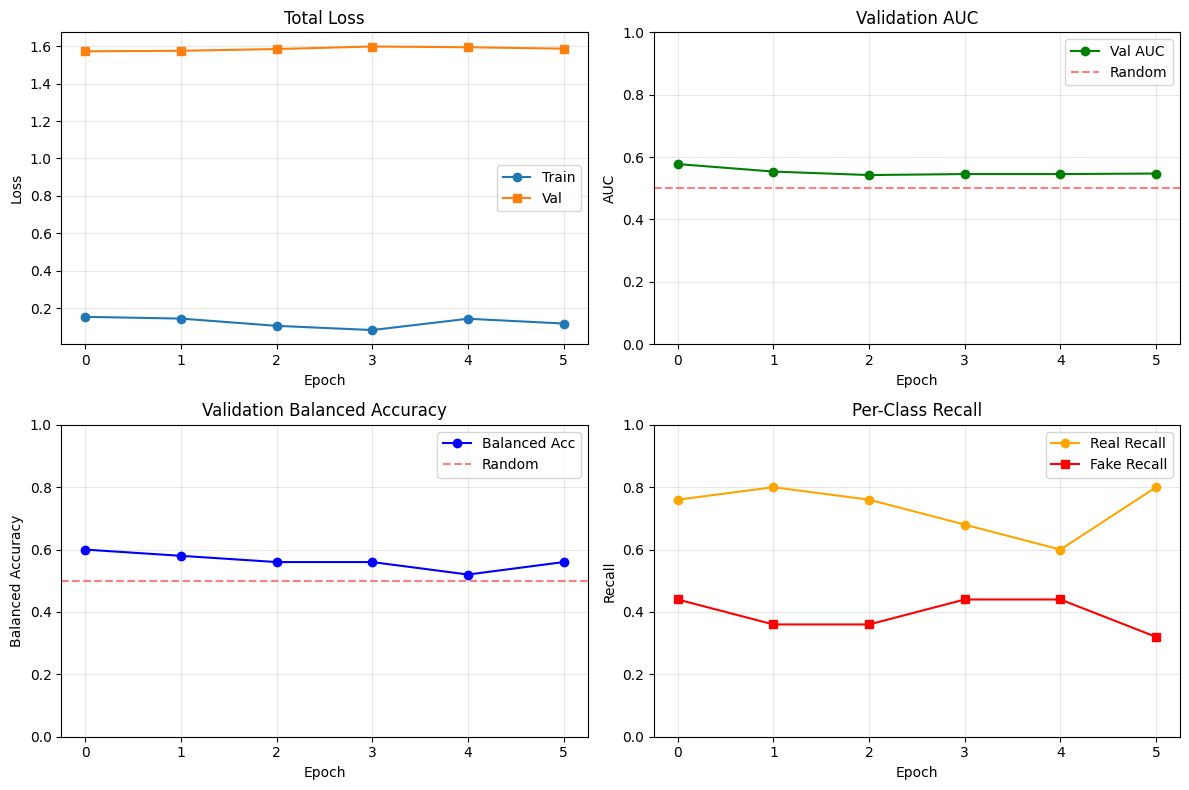


🎉 Ready for evaluation! Run Cell 19 to test on test set.


In [51]:
# === Cell 18: Detector training loop (FIXED METRIC NAMES) ===

# Detector training configuration
DETECTOR_EPOCHS = 8
DETECTOR_LR = 1e-4
PATIENCE = 5

# Load best ART checkpoint
best_art_epoch = ART_EPOCHS
checkpoint = torch.load(CKPT_DIR / f"art_epoch{best_art_epoch}.pt")
audio_temp_head.load_state_dict(checkpoint["audio_temp_state"])
visual_temp_head.load_state_dict(checkpoint["visual_temp_state"])
audio_proj_head.load_state_dict(checkpoint["audio_proj_state"])
visual_proj_head.load_state_dict(checkpoint["visual_proj_state"])
print(f"✓ Loaded ART checkpoint from epoch {best_art_epoch}")

# Freeze ART heads
audio_temp_head.eval()
visual_temp_head.eval()
audio_proj_head.eval()
visual_proj_head.eval()
for p in audio_temp_head.parameters(): p.requires_grad = False
for p in visual_temp_head.parameters(): p.requires_grad = False
for p in audio_proj_head.parameters(): p.requires_grad = False
for p in visual_proj_head.parameters(): p.requires_grad = False

# Optimizer (only detector parameters)
detector_optimizer = AdamW(detector.parameters(), lr=DETECTOR_LR, weight_decay=1e-2)

print(f"\n{'='*60}")
print("DETECTOR TRAINING")
print(f"{'='*60}")
print(f"Epochs: {DETECTOR_EPOCHS}")
print(f"Learning rate: {DETECTOR_LR}")
print(f"Patience: {PATIENCE}")
print(f"Trainable params: {sum(p.numel() for p in detector.parameters()):,}")
print(f"Loss function: Focal Loss + Alignment Retention")
print(f"{'='*60}\n")

# Training loop
best_metric = 0  # Track best balanced accuracy
patience_counter = 0

# Store training history
history = {
    'train_loss': [], 'train_focal': [], 'train_align': [],
    'val_loss': [], 'val_auc': [], 'val_balanced_acc': [],
    'val_f1': [], 'val_real_recall': [], 'val_fake_recall': []
}

for epoch in range(1, DETECTOR_EPOCHS + 1):
    # Training
    detector.train()
    running_loss = 0.0
    running_focal = 0.0
    running_align = 0.0
    num_batches = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{DETECTOR_EPOCHS}")
    for batch in pbar:
        audio_feats = batch["audio_features"].to(DEVICE)
        audio_mask = batch["audio_mask"].to(DEVICE)
        visual_feats = batch["visual_features"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        # Forward (frozen ART heads)
        with torch.no_grad():
            audio_global = audio_temp_head(audio_feats, mask=audio_mask)
            visual_global = visual_temp_head(visual_feats)
            audio_proj = audio_proj_head(audio_global)
            visual_proj = visual_proj_head(visual_global)

        # Detector forward
        logits = detector(audio_global, visual_global, audio_proj)

        # Loss
        loss, metrics = detector_loss_fn(logits, labels, audio_proj, visual_proj)

        # Backward
        detector_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(detector.parameters(), max_norm=1.0)
        detector_optimizer.step()

        # Accumulate metrics (use 'focal' not 'bce')
        running_loss += metrics["total"]
        running_focal += metrics["focal"]  # Changed from 'bce'
        running_align += metrics["align"]
        num_batches += 1

        pbar.set_postfix({
            "loss": running_loss / num_batches,
            "focal": running_focal / num_batches,
        })

    avg_loss = running_loss / num_batches
    avg_focal = running_focal / num_batches
    avg_align = running_align / num_batches

    print(f"\nEpoch {epoch} Train:")
    print(f"  Total Loss: {avg_loss:.4f}")
    print(f"  Focal Loss: {avg_focal:.4f}")
    print(f"  Align Loss: {avg_align:.4f}")

    # Store training metrics
    history['train_loss'].append(avg_loss)
    history['train_focal'].append(avg_focal)
    history['train_align'].append(avg_align)

    # Validation with enhanced metrics
    val_metrics = validate(
        val_loader, audio_temp_head, visual_temp_head,
        audio_proj_head, visual_proj_head, detector,
        detector_loss_fn, DEVICE
    )

    print(f"\nEpoch {epoch} Val:")
    print(f"  Total Loss: {val_metrics['loss']:.4f}")
    print(f"  AUC: {val_metrics['auc']:.4f}")
    print(f"  Balanced Acc: {val_metrics['balanced_acc']:.4f}")
    print(f"  F1 Score: {val_metrics['f1']:.4f}")
    print(f"  Real Recall: {val_metrics['real_recall']:.4f}")
    print(f"  Fake Recall: {val_metrics['fake_recall']:.4f}")

    # Store validation metrics
    history['val_loss'].append(val_metrics['loss'])
    history['val_auc'].append(val_metrics['auc'])
    history['val_balanced_acc'].append(val_metrics['balanced_acc'])
    history['val_f1'].append(val_metrics['f1'])
    history['val_real_recall'].append(val_metrics['real_recall'])
    history['val_fake_recall'].append(val_metrics['fake_recall'])

    # Save checkpoint every epoch
    torch.save({
        "epoch": epoch,
        "detector_state": detector.state_dict(),
        "optimizer": detector_optimizer.state_dict(),
        "val_metrics": val_metrics,
        "history": history,
    }, CKPT_DIR / f"detector_epoch{epoch}.pt")

    # Track best model based on balanced accuracy
    metric_to_track = val_metrics['balanced_acc']
    metric_name = "Balanced Accuracy"

    # Alternative tracking metrics (uncomment to use):
    # metric_to_track = val_metrics['f1']
    # metric_name = "F1 Score"
    # metric_to_track = val_metrics['auc']
    # metric_name = "AUC"

    if metric_to_track > best_metric:
        best_metric = metric_to_track
        patience_counter = 0
        torch.save({
            "epoch": epoch,
            "detector_state": detector.state_dict(),
            "val_metrics": val_metrics,
            "history": history,
        }, CKPT_DIR / "detector_best.pt")
        print(f"\n✓ New best {metric_name}: {best_metric:.4f} (saved detector_best.pt)")
    else:
        patience_counter += 1
        print(f"  No improvement. Patience: {patience_counter}/{PATIENCE}")

    # Early stopping
    if patience_counter >= PATIENCE:
        print(f"\n⚠️ Early stopping triggered at epoch {epoch}")
        break

    print("-" * 60)

# ... (keep all the training loop code above, only replace from "Training complete" onwards)

# Training complete
print(f"\n{'='*60}")
print("✅ DETECTOR TRAINING COMPLETE")
print(f"{'='*60}")
print(f"  Best {metric_name}: {best_metric:.4f}")

# Load and display best model metrics (FIX: add weights_only=False)
print(f"\n📊 Best Model Summary:")
try:
    best_ckpt = torch.load(CKPT_DIR / "detector_best.pt", weights_only=False)
    best_metrics = best_ckpt['val_metrics']
    print(f"  Epoch: {best_ckpt['epoch']}")
    print(f"  AUC: {best_metrics['auc']:.4f}")
    print(f"  Balanced Accuracy: {best_metrics['balanced_acc']:.4f}")
    print(f"  F1 Score: {best_metrics['f1']:.4f}")
    print(f"  Real Recall (TPR): {best_metrics['real_recall']:.4f}")
    print(f"  Fake Recall (TNR): {best_metrics['fake_recall']:.4f}")
except Exception as e:
    print(f"⚠️ Could not load best checkpoint: {e}")
    print(f"   Using final epoch metrics instead")
    print(f"  AUC: {val_metrics['auc']:.4f}")
    print(f"  Balanced Accuracy: {val_metrics['balanced_acc']:.4f}")
    print(f"  F1 Score: {val_metrics['f1']:.4f}")

print(f"{'='*60}")

# Save training history
import pickle
with open(CKPT_DIR / "training_history.pkl", "wb") as f:
    pickle.dump(history, f)
print(f"\n✓ Training history saved to {CKPT_DIR / 'training_history.pkl'}")

# Optional: Plot training curves (if matplotlib available)
try:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # Loss curves
    axes[0, 0].plot(history['train_loss'], label='Train', marker='o')
    axes[0, 0].plot(history['val_loss'], label='Val', marker='s')
    axes[0, 0].set_title('Total Loss')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # AUC
    axes[0, 1].plot(history['val_auc'], label='Val AUC', color='green', marker='o')
    axes[0, 1].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
    axes[0, 1].set_title('Validation AUC')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('AUC')
    axes[0, 1].set_ylim([0, 1])
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # Balanced Accuracy
    axes[1, 0].plot(history['val_balanced_acc'], label='Balanced Acc', color='blue', marker='o')
    axes[1, 0].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
    axes[1, 0].set_title('Validation Balanced Accuracy')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Balanced Accuracy')
    axes[1, 0].set_ylim([0, 1])
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # Per-class Recall
    axes[1, 1].plot(history['val_real_recall'], label='Real Recall', color='orange', marker='o')
    axes[1, 1].plot(history['val_fake_recall'], label='Fake Recall', color='red', marker='s')
    axes[1, 1].set_title('Per-Class Recall')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Recall')
    axes[1, 1].set_ylim([0, 1])
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(CKPT_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
    print(f"✓ Training curves saved to {CKPT_DIR / 'training_curves.png'}")
    plt.show()

except ImportError:
    print("⚠️ matplotlib not available, skipping plots")
except Exception as e:
    print(f"⚠️ Could not generate plots: {e}")

print("\n🎉 Ready for evaluation! Run Cell 19 to test on test set.")

In [53]:
# === Cell 19: Window-level inference (FIXED) ===

@torch.no_grad()
def predict_windows(dataloader, audio_temp_head, visual_temp_head,
                   audio_proj_head, visual_proj_head, detector, device):
    """Inference on all windows."""
    audio_temp_head.eval()
    visual_temp_head.eval()
    audio_proj_head.eval()
    visual_proj_head.eval()
    detector.eval()

    results = []

    for batch in tqdm(dataloader, desc="Inference"):
        audio_feats = batch["audio_features"].to(device)
        audio_mask = batch["audio_mask"].to(device)
        visual_feats = batch["visual_features"].to(device)
        ids = batch["id"]

        # Forward
        audio_global = audio_temp_head(audio_feats, mask=audio_mask)
        visual_global = visual_temp_head(visual_feats)
        audio_proj = audio_proj_head(audio_global)
        visual_proj = visual_proj_head(visual_global)

        logits = detector(audio_global, visual_global, audio_proj)
        probs = torch.sigmoid(logits)

        # Alignment scores
        align_scores = F.cosine_similarity(audio_proj, visual_proj, dim=1)

        for i in range(len(ids)):
            results.append({
                "id": ids[i],
                "logit": logits[i].item(),
                "prob": probs[i].item(),
                "alignment": align_scores[i].item(),
            })

    return results

print("="*60)
print("WINDOW-LEVEL INFERENCE")
print("="*60)

# Load best detector (FIX: add weights_only=False)
try:
    best_ckpt = torch.load(CKPT_DIR / "detector_best.pt", weights_only=False)
    detector.load_state_dict(best_ckpt["detector_state"])

    # Get metrics from checkpoint
    val_metrics = best_ckpt.get('val_metrics', {})
    val_auc = val_metrics.get('auc', 0.0)
    val_bal_acc = val_metrics.get('balanced_acc', 0.0)
    best_epoch = best_ckpt.get('epoch', '?')

    print(f"✓ Loaded best detector checkpoint:")
    print(f"  Epoch: {best_epoch}")
    print(f"  Val AUC: {val_auc:.4f}")
    print(f"  Val Balanced Acc: {val_bal_acc:.4f}")

except FileNotFoundError:
    print("⚠️ detector_best.pt not found, using current model state")
except Exception as e:
    print(f"⚠️ Could not load checkpoint: {e}")
    print("   Using current model state")

# Run inference on test set
print(f"\nRunning inference on test set ({len(test_dataset)} windows)...")
window_predictions = predict_windows(
    test_loader, audio_temp_head, visual_temp_head,
    audio_proj_head, visual_proj_head, detector, DEVICE
)

# Create DataFrame
win_df = pd.DataFrame(window_predictions)

# Merge with ground truth labels
print(f"✓ Generated {len(win_df)} predictions")

# Load test metadata
test_df = pd.read_csv(SPLITS_DIR / "test_preprocessed.csv")

# Merge predictions with labels
win_df = win_df.merge(
    test_df[["id", "label", "video_path", "speaker_id", "category"]],
    on="id",
    how="left"
)

print(f"\n✓ Inference complete: {len(win_df)} windows")

# Check for missing labels
if win_df['label'].isna().any():
    print(f"⚠️ Warning: {win_df['label'].isna().sum()} windows missing labels")
    win_df = win_df.dropna(subset=['label'])
    print(f"   Kept {len(win_df)} windows with valid labels")

# Display sample predictions
print("\n" + "="*60)
print("SAMPLE PREDICTIONS")
print("="*60)
print(win_df[["id", "prob", "label", "alignment", "category"]].head(10).to_string(index=False))

# Basic window-level statistics
print("\n" + "="*60)
print("WINDOW-LEVEL STATISTICS")
print("="*60)

y_true_win = win_df['label'].values
y_pred_win = win_df['prob'].values

# Compute metrics
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score

auc_win = roc_auc_score(y_true_win, y_pred_win)
print(f"Window-level AUC: {auc_win:.4f}")

# Find optimal threshold (Youden's J statistic)
fpr, tpr, thresholds = roc_curve(y_true_win, y_pred_win)
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
best_thresh = thresholds[best_idx]

y_pred_binary = (y_pred_win >= best_thresh).astype(int)
acc_win = accuracy_score(y_true_win, y_pred_binary)

print(f"Optimal threshold: {best_thresh:.3f}")
print(f"Accuracy at threshold: {acc_win:.4f}")

# Per-class metrics
real_windows = win_df[win_df['label'] == 0]
fake_windows = win_df[win_df['label'] == 1]

print(f"\nReal windows (label=0):")
print(f"  Count: {len(real_windows)}")
print(f"  Mean prob: {real_windows['prob'].mean():.4f}")
print(f"  Std prob: {real_windows['prob'].std():.4f}")

print(f"\nFake windows (label=1):")
print(f"  Count: {len(fake_windows)}")
print(f"  Mean prob: {fake_windows['prob'].mean():.4f}")
print(f"  Std prob: {fake_windows['prob'].std():.4f}")

# Alignment analysis
print(f"\nAlignment scores:")
print(f"  Real windows: {real_windows['alignment'].mean():.4f} ± {real_windows['alignment'].std():.4f}")
print(f"  Fake windows: {fake_windows['alignment'].mean():.4f} ± {fake_windows['alignment'].std():.4f}")

# Distribution of predictions
print(f"\nPrediction distribution:")
print(f"  Min prob: {win_df['prob'].min():.4f}")
print(f"  Max prob: {win_df['prob'].max():.4f}")
print(f"  Median prob: {win_df['prob'].median():.4f}")

# Save window-level predictions
win_df.to_csv(CKPT_DIR / "window_predictions.csv", index=False)
print(f"\n✓ Window predictions saved to {CKPT_DIR / 'window_predictions.csv'}")

print("\n" + "="*60)
print("✅ Window-level inference complete!")
print("="*60)
print("Next: Run Cell 20 for video-level aggregation and final metrics")

WINDOW-LEVEL INFERENCE
✓ Loaded best detector checkpoint:
  Epoch: 1
  Val AUC: 0.5776
  Val Balanced Acc: 0.6000

Running inference on test set (50 windows)...


Inference: 100%|██████████| 7/7 [00:02<00:00,  3.30it/s]

✓ Generated 50 predictions

✓ Inference complete: 50 windows

SAMPLE PREDICTIONS
              id     prob  label  alignment category
ee1336e77536aed7 0.747310      1  -0.042295        D
f6577ecbad53f205 0.212438      0   0.033957        A
8222a40befef88d5 0.743588      1  -0.286470        D
5675d133a512a2cc 0.818213      1   0.065271        D
5ed5226d9426efb5 0.449043      0  -0.039480        A
9a36402a51bf55c1 0.419068      1   0.020418        C
f0799de649538ba3 0.658154      1  -0.012717        C
b1c6fda2de02211c 0.651482      1   0.040136        C
66c1607030f43420 0.120029      1   0.066057        C
c69826ebed7c914d 0.163365      0   0.218167        A

WINDOW-LEVEL STATISTICS
Window-level AUC: 0.6144
Optimal threshold: 0.532
Accuracy at threshold: 0.6200

Real windows (label=0):
  Count: 25
  Mean prob: 0.4377
  Std prob: 0.1876

Fake windows (label=1):
  Count: 25
  Mean prob: 0.5131
  Std prob: 0.2191

Alignment scores:
  Real windows: 0.0693 ± 0.1042
  Fake windows: 0.0186 ± 0.1

In [54]:
# === Cell 20: Video-level aggregation and final metrics (FIXED) ===

def aggregate_windows_to_video(window_results, method="mean"):
    """Aggregate window predictions to video-level score."""
    probs = np.array([r["prob"] for r in window_results])
    aligns = np.array([r["alignment"] for r in window_results])

    if method == "mean":
        return probs.mean()
    elif method == "max":
        return probs.max()
    elif method == "topk":
        k = max(1, int(len(probs) * 0.33))
        top_indices = np.argsort(probs)[-k:]
        return probs[top_indices].mean()
    elif method == "align_weighted":
        # Weight by (1 - alignment): high misalignment = more suspicious
        weights = 1.0 - aligns
        weights = weights / (weights.sum() + 1e-8)
        return (probs * weights).sum()
    else:
        raise ValueError(f"Unknown method: {method}")

print("="*60)
print("VIDEO-LEVEL AGGREGATION")
print("="*60)

# Load window predictions if not already in memory
if 'win_df' not in locals():
    win_df = pd.read_csv(CKPT_DIR / "window_predictions.csv")
    print(f"✓ Loaded window predictions: {len(win_df)} windows")

# Aggregate per video
print(f"\nAggregating {len(win_df)} windows to video-level scores...")
video_groups = win_df.groupby("video_path")
video_scores = []

for vpath, group in tqdm(video_groups, desc="Aggregating"):
    records = group.to_dict("records")

    # Different aggregation methods
    score_mean = aggregate_windows_to_video(records, method="mean")
    score_max = aggregate_windows_to_video(records, method="max")
    score_topk = aggregate_windows_to_video(records, method="topk")
    score_align = aggregate_windows_to_video(records, method="align_weighted")

    # Video label (any fake window → fake video)
    label = int(group["label"].iloc[0])

    video_scores.append({
        "video_path": vpath,
        "label": label,
        "score_mean": score_mean,
        "score_max": score_max,
        "score_topk": score_topk,
        "score_align": score_align,
        "num_windows": len(group),
        "speaker_id": group["speaker_id"].iloc[0],
        "category": group["category"].iloc[0],
    })

vid_df = pd.DataFrame(video_scores)
print(f"✓ Aggregated to {len(vid_df)} videos")

# Display sample video scores
print("\n" + "="*60)
print("SAMPLE VIDEO SCORES")
print("="*60)
print(vid_df[["label", "score_mean", "score_topk", "num_windows", "category"]].head(10).to_string(index=False))

# Compute metrics for each aggregation method
print("\n" + "="*60)
print("VIDEO-LEVEL EVALUATION METRICS")
print("="*60)

from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score, f1_score

results_summary = []

for method_name, score_col in [
    ("Mean", "score_mean"),
    ("Max", "score_max"),
    ("Top-33%", "score_topk"),
    ("Align-weighted", "score_align")
]:
    y_true = vid_df["label"].values
    y_scores = vid_df[score_col].values

    # ROC-AUC
    auc = roc_auc_score(y_true, y_scores)

    # EER (Equal Error Rate)
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    fnr = 1 - tpr
    eer_idx = np.nanargmin(np.abs(fpr - fnr))
    eer = fpr[eer_idx]
    eer_threshold = thresholds[eer_idx]

    # Binary predictions at EER threshold
    y_pred = (y_scores >= eer_threshold).astype(int)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"\n{method_name} Aggregation:")
    print(f"  AUC: {auc:.4f}")
    print(f"  EER: {eer:.4f} (threshold={eer_threshold:.3f})")
    print(f"  Balanced Accuracy: {bal_acc:.4f}")
    print(f"  F1 Score: {f1:.4f}")

    results_summary.append({
        "Method": method_name,
        "AUC": auc,
        "EER": eer,
        "Balanced Acc": bal_acc,
        "F1": f1,
    })

# Summary table
print("\n" + "="*60)
print("SUMMARY TABLE")
print("="*60)
summary_df = pd.DataFrame(results_summary)
print(summary_df.to_string(index=False))

# Save results
vid_df.to_csv(CKPT_DIR / "video_level_scores.csv", index=False)
summary_df.to_csv(CKPT_DIR / "evaluation_summary.csv", index=False)

print("\n" + "="*60)
print("✅ EVALUATION COMPLETE!")
print("="*60)
print(f"\nSaved files:")
print(f"  • {CKPT_DIR / 'window_predictions.csv'}")
print(f"  • {CKPT_DIR / 'video_level_scores.csv'}")
print(f"  • {CKPT_DIR / 'evaluation_summary.csv'}")

# Final recommendations
print("\n📊 NEXT STEPS:")
if vid_df['score_mean'].mean() > 0.9:
    print("  ⚠️ Model predicts mostly FAKE (mean score > 0.9)")
    print("     → Check class balance in training")
elif vid_df['score_mean'].mean() < 0.1:
    print("  ⚠️ Model predicts mostly REAL (mean score < 0.1)")
    print("     → Check class balance in training")

if TESTING_MODE:
    print("\n  💡 You're in TESTING_MODE with only 50 samples")
    print("     Set TESTING_MODE = False in Cell 2 for real training!")

print("\n🎉 Pipeline complete! Check the saved CSV files for detailed results.")

VIDEO-LEVEL AGGREGATION

Aggregating 50 windows to video-level scores...


Aggregating: 100%|██████████| 48/48 [00:00<00:00, 1215.73it/s]

✓ Aggregated to 48 videos

SAMPLE VIDEO SCORES
 label  score_mean  score_topk  num_windows category
     1    0.446574    0.446574            1        D
     1    0.517692    0.517692            1        D
     1    0.554073    0.554073            1        D
     1    0.721768    0.721768            1        D
     1    0.818213    0.818213            1        D
     1    0.670093    0.670093            1        D
     1    0.872892    0.872892            1        D
     1    0.743588    0.743588            1        D
     1    0.554941    0.554941            1        D
     1    0.296450    0.296450            1        D

VIDEO-LEVEL EVALUATION METRICS

Mean Aggregation:
  AUC: 0.6104
  EER: 0.3478 (threshold=0.518)
  Balanced Accuracy: 0.6261
  F1 Score: 0.6250

Max Aggregation:
  AUC: 0.5983
  EER: 0.3913 (threshold=0.518)
  Balanced Accuracy: 0.6043
  F1 Score: 0.6122

Top-33% Aggregation:
  AUC: 0.5983
  EER: 0.3913 (threshold=0.518)
  Balanced Accuracy: 0.6043
  F1 Score: 0.6122
